In [1]:
import trimesh
import pyvista as pv
import numpy as np
import matplotlib.pyplot as plt
import math

In [2]:
from hac.data import load_data
from hac.geometry import *
from hac.constants import *

In [3]:
def get_lcs(model_num, cam_idx, curve_type="intensity"):
    ds_real = load_data(model_num, origin="real", curve_type=curve_type)
    ds_blender = load_data(model_num, origin="simulated", curve_type=curve_type)
    lc_real = ds_real.data[cam_idx]
    lc_blender = ds_blender.data[cam_idx]

    sim_root = Path("workspaces/david/out/sim_lc")
    lc_sim = np.load(sim_root / f"model_{model_num:02d}" / f"cam_{cam_idx}_{curve_type}.npy")
    return lc_real, lc_blender, lc_sim

In [4]:
def plot_lcs(
    model_num,
    cam_idx,
    *,
    curve_type="intensity",
    ncols=None,
    figsize_per_plot=(4.2, 2.4),
    sharex=True,
    sharey=False,
    legend=True,
    max_cols=4,
):
    """
    Plot light curves for one camera or many cameras.

    Parameters
    ----------
    model_num : int
        Model number.

    cam_idx : int or list-like[int]
        Single camera index, or a list/array of camera indices such as POSITION_IDS.

    curve_type : str
        Curve type passed to get_lcs.

    ncols : int | None
        Number of subplot columns. If None, chosen automatically.

    figsize_per_plot : tuple[float, float]
        Width and height per subplot.

    sharex, sharey : bool
        Whether subplots share x/y axes.

    legend : bool
        Whether to draw one shared legend for the whole figure.

    max_cols : int
        Maximum number of columns when ncols is selected automatically.
    """

    # Normalize cam_idx so the rest of the function always works with a list.
    if np.isscalar(cam_idx):
        cam_indices = [int(cam_idx)]
    else:
        cam_indices = list(cam_idx)

    n = len(cam_indices)

    if n == 0:
        raise ValueError("cam_idx must contain at least one camera index.")

    # Automatically choose grid shape.
    # For 28 plots this gives 4 columns x 7 rows by default.
    if ncols is None:
        ncols = min(max_cols, math.ceil(math.sqrt(n)))

    nrows = math.ceil(n / ncols)

    fig_width = figsize_per_plot[0] * ncols
    fig_height = figsize_per_plot[1] * nrows

    fig, axes = plt.subplots(
        nrows=nrows,
        ncols=ncols,
        figsize=(fig_width, fig_height),
        sharex=sharex,
        sharey=sharey,
        squeeze=False,
    )

    axes_flat = axes.ravel()

    for ax, cam in zip(axes_flat, cam_indices):
        lc_real, lc_blender, lc_sim = get_lcs(
            model_num,
            cam,
            curve_type=curve_type,
        )

        x_real = np.linspace(0, 360, len(lc_real))
        x_blender = np.linspace(0, 360, len(lc_blender))
        x_sim = np.linspace(0, 360, len(lc_sim))

        ax.plot(
            x_real,
            lc_real,
            label="real",
            linewidth=1.5,
            zorder=1,
        )

        ax.plot(
            x_blender,
            lc_blender,
            label="blender",
            linewidth=1.5,
            linestyle="-",
            zorder=3,
        )

        ax.plot(
            x_sim,
            lc_sim,
            label="simulated",
            linewidth=1.5,
            linestyle="--",
            zorder=4,
        )

        ax.set_title(f"cam {cam}", fontsize=10)
        ax.grid(True, alpha=0.25)
        ax.set_xlim(0, 360)

    # Hide unused axes when the grid has more slots than cameras.
    for ax in axes_flat[n:]:
        ax.set_visible(False)

    # Axis labels only on outer plots to reduce clutter.
    for ax in axes[-1, :]:
        if ax.get_visible():
            ax.set_xlabel("phase / angle [deg]")

    for ax in axes[:, 0]:
        if ax.get_visible():
            ax.set_ylabel("intensity")

    fig.suptitle(
        f"model_{model_num:02d} {curve_type} lightcurves",
        fontsize=16,
        y=1.0,
    )

    if legend:
        handles, labels = axes_flat[0].get_legend_handles_labels()
        fig.legend(
            handles,
            labels,
            loc="upper center",
            bbox_to_anchor=(0.5, 0.985),
            ncol=3,
            frameon=False,
        )

    fig.tight_layout(rect=(0, 0, 1, 0.96))
    plt.show()

    return fig, axes

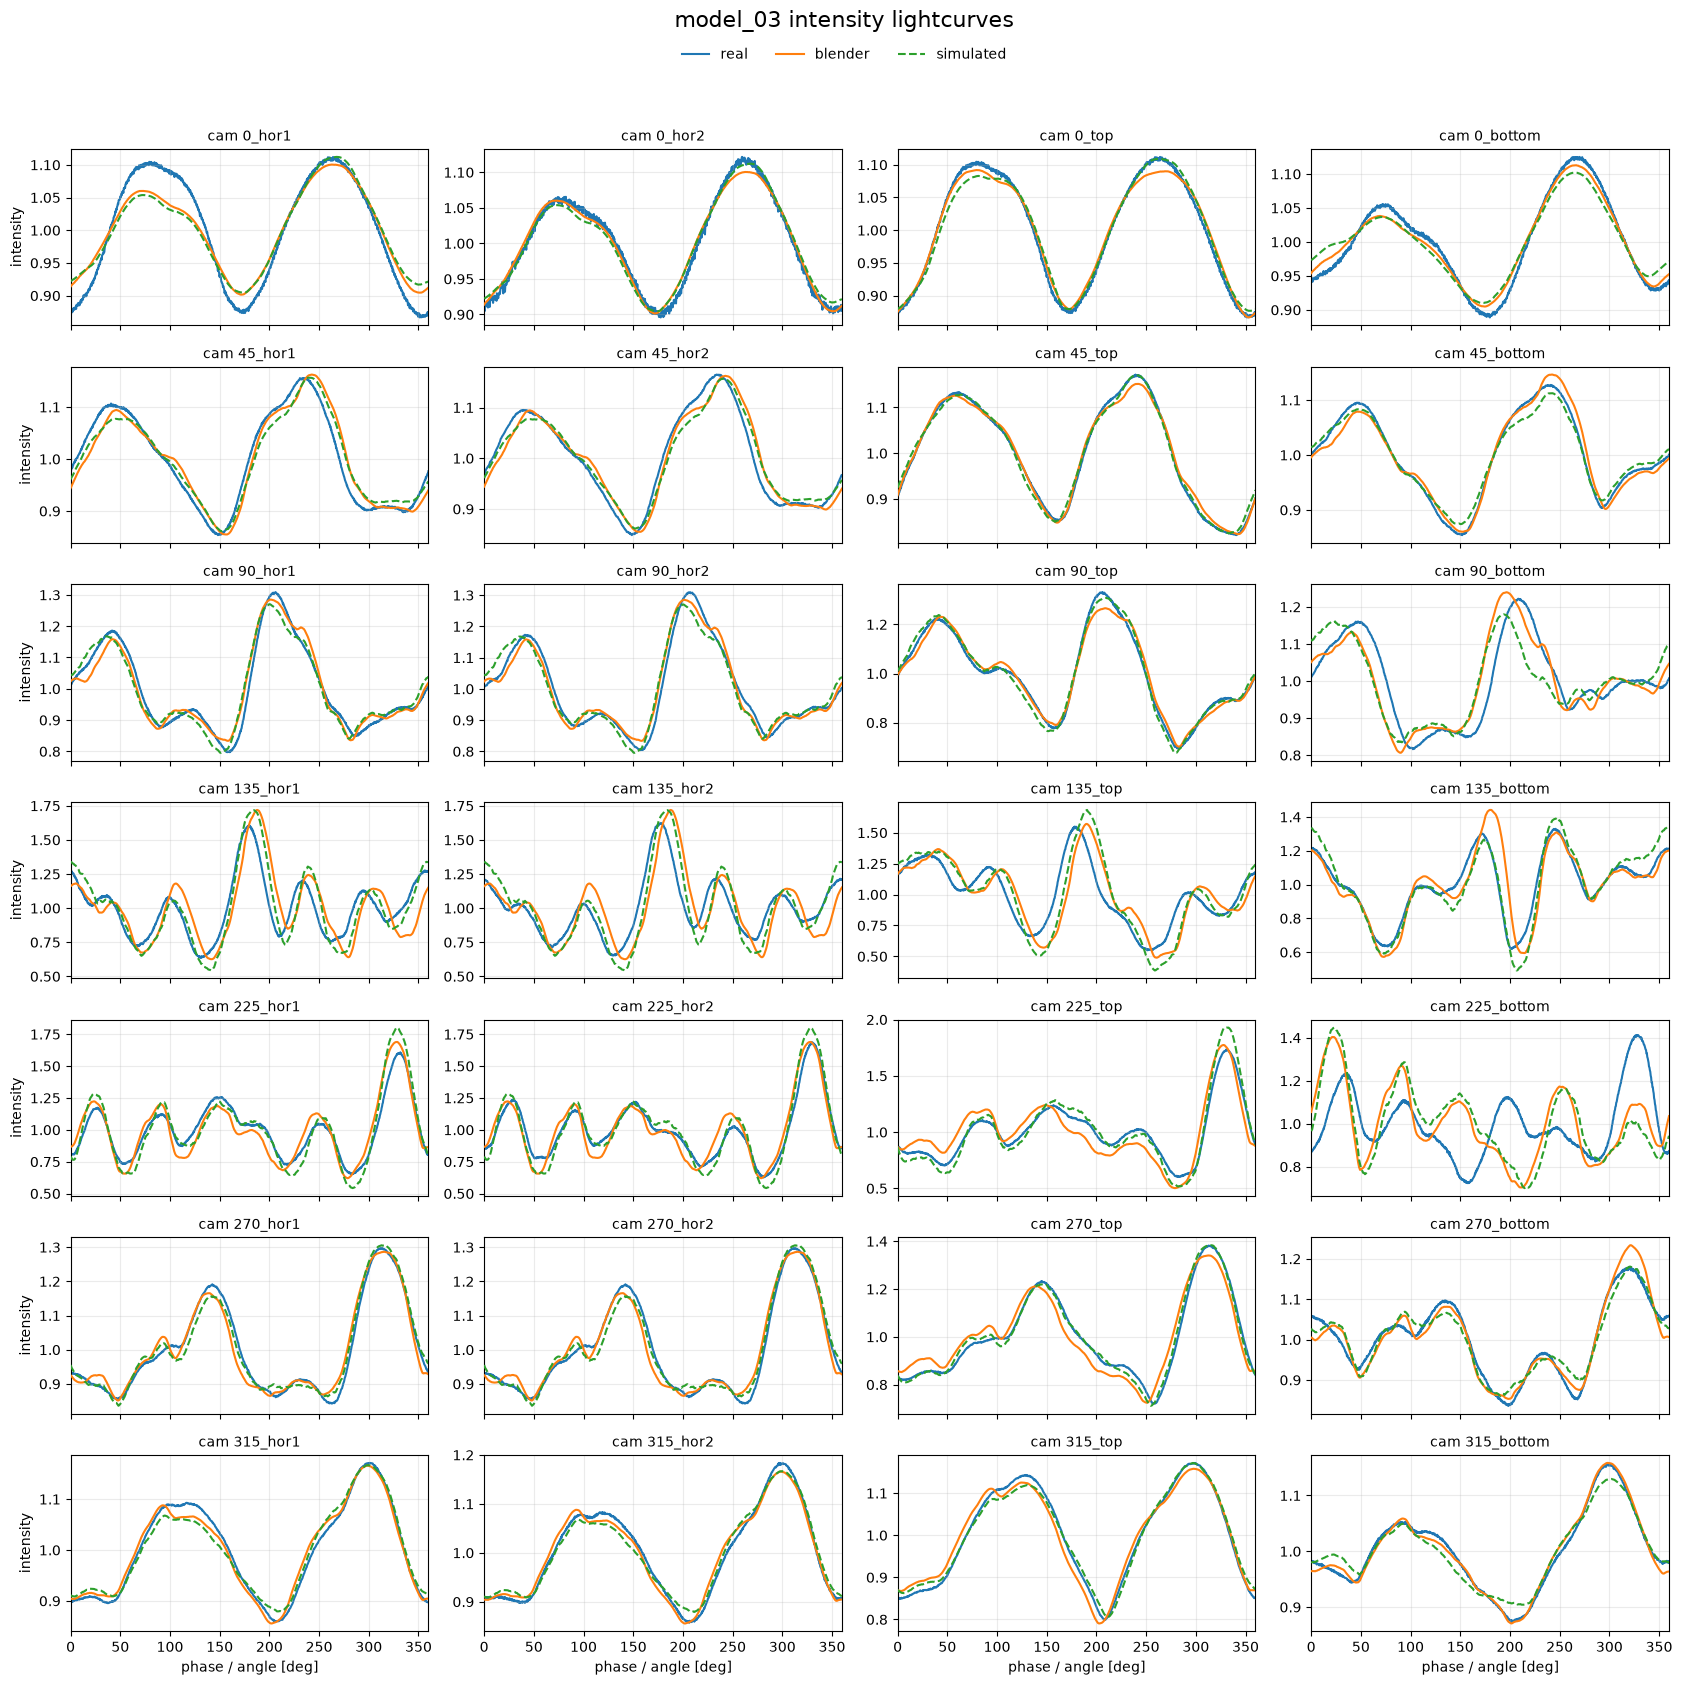

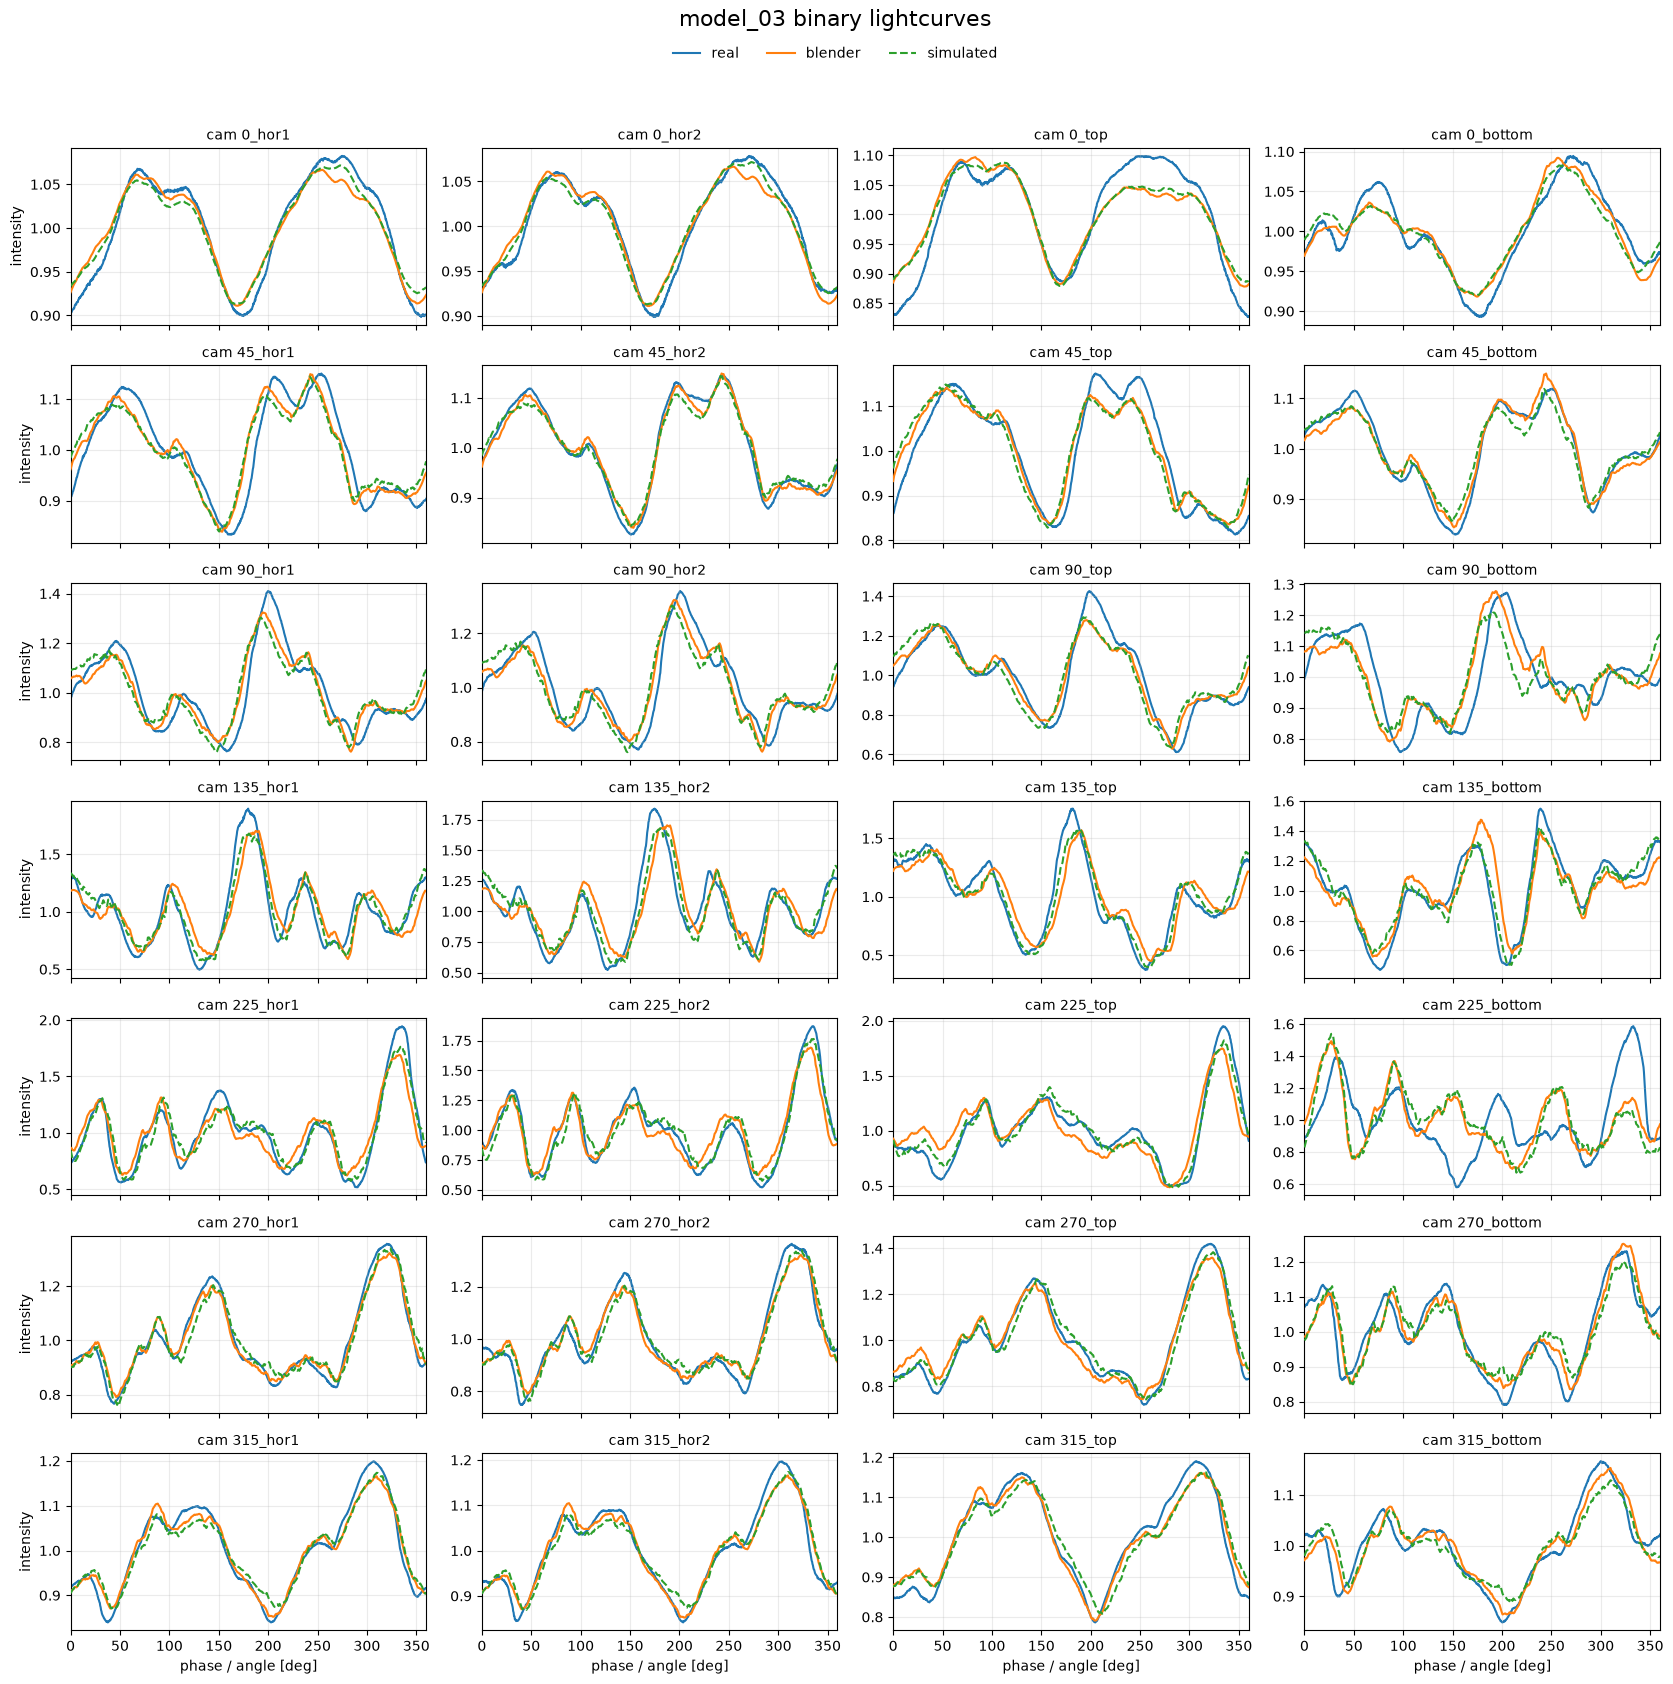

In [5]:
plot_lcs(model_num=3, cam_idx=POSITION_IDS, curve_type="intensity");
plot_lcs(model_num=3, cam_idx=POSITION_IDS, curve_type="binary");